# Chances, Luck and Style at International Football Tournaments
**CS-215 Final Project · Ahmed · Fall 2026**

Every big tournament sparks the same arguments. Was the champion actually the best team, or did they ride their luck? Do African, South American and European teams really play differently? Is everyone pressing higher now?

This notebook tests those arguments with data. It uses **314 matches** from six recent men's international tournaments (the 2018 and 2022 World Cups, Euro 2020 and 2024, AFCON 2023 and Copa América 2024): about **7,600 shots** and about **1.1 million on-ball events**.

### Questions
1. **What makes a shot likely to become a goal?** I built my own *expected goals* (xG) model and compared it with the professional one.
2. **Which teams finished their chances better or worse than expected, and were the champions lucky?**
3. **Do teams fall into distinct playing styles, and has tournament football changed since 2018?**

### Data
All data is from [StatsBomb Open Data](https://github.com/statsbomb/open-data), a free, public release of professional event data. Every pass, shot, pressure and tackle comes with pitch coordinates. Each shot also carries a **freeze frame**: the position of every visible player at the moment of the shot. Coordinates run from 0 to 120 along the pitch (the attacking team always shoots toward x = 120) and from 0 to 80 across it. The goal is centred at (120, 40).

*Data credit: StatsBomb (Hudl).*

## 1. Setup
This loads the libraries. [`mplsoccer`](https://mplsoccer.readthedocs.io/) draws football pitches, and [`adjustText`](https://github.com/Phlya/adjustText) keeps chart labels from overlapping. Every chart uses one fixed, colourblind-safe palette.

In [1]:
# In Colab, mplsoccer (pitch drawing) is not pre-installed
%pip install -q mplsoccer adjustText

import json, os
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
from adjustText import adjust_text   # nudges chart labels so they don't overlap
from mplsoccer import VerticalPitch
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score, log_loss, silhouette_score

os.makedirs("figures", exist_ok=True)   # charts are also saved here for the website
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
# One fixed, colorblind-checked palette used across every chart
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left"})

Note: you may need to restart the kernel to use updated packages.


## 2. Getting the data
StatsBomb stores one JSON file per match. `competitions.json` gives the ID for each tournament. The code downloads each tournament's match list, then the event file for every match (about 900 MB), and caches everything in `data/raw/` so re-running the notebook doesn't download it again.

In [2]:
BASE = "https://raw.githubusercontent.com/statsbomb/open-data/master/data"
TOURNAMENTS = {  # (competition_id, season_id): label  -- ids come from competitions.json
    (43, 3): "World Cup 2018", (43, 106): "World Cup 2022",
    (55, 43): "Euro 2020", (55, 282): "Euro 2024",
    (1267, 107): "AFCON 2023", (223, 282): "Copa America 2024"}
RAW = "data/raw"; os.makedirs(RAW, exist_ok=True)

def get_json(path):
    """Download a StatsBomb file once, then read it from the local cache."""
    local = os.path.join(RAW, path.replace("/", "_"))
    if not os.path.exists(local):
        r = requests.get(f"{BASE}/{path}", timeout=60); r.raise_for_status()
        open(local, "wb").write(r.content)
    return json.load(open(local, encoding="utf-8"))

rows = []
for (cid, sid), label in TOURNAMENTS.items():
    for m in get_json(f"matches/{cid}/{sid}.json"):
        rows.append({"match_id": m["match_id"], "tournament": label,
            "stage": m["competition_stage"]["name"],
            "home_team": m["home_team"]["home_team_name"], "away_team": m["away_team"]["away_team_name"],
            "home_score": m["home_score"], "away_score": m["away_score"]})
matches = pd.DataFrame(rows)

# ~900 MB of event JSON; 16 parallel downloads takes about a minute
with ThreadPoolExecutor(16) as ex:
    events = dict(zip(matches.match_id, ex.map(lambda i: get_json(f"events/{i}.json"), matches.match_id)))
matches.groupby("tournament").size().rename("matches").to_frame()

,matches
tournament,
AFCON 2023,52
Copa America 2024,32
Euro 2020,51
Euro 2024,51
World Cup 2018,64
World Cup 2022,64


## 3. Wrangling: from a million events to three tidy tables
The raw files are deeply nested JSON (an event holds a `shot` dict, which holds a `freeze_frame` list of players, and so on). I flatten them into two tables:

**`shots`: one row per shot.** From each shot's coordinates I calculate:
- **distance** to the centre of the goal
- **angle**: how wide the goal mouth looks from the shot spot, between the two posts at (120, 36) and (120, 44), using the formula angle = atan2(8·dx, dx² + dy² − 16)
- four **freeze-frame features**: how many defenders stand inside the triangle formed by the shooter and the two posts; whether the keeper is in that triangle; how far the keeper is off his line; and the distance to the nearest defender. Testing whether a defender is inside the triangle uses a cross-product sign test (see *New techniques*).

**`team_match_style`: one row per team per match.** These are style metrics built from open-play passes and pressures (set pieces are excluded):

| metric | meaning |
|---|---|
| possession_share | the team's share of all passes in the match |
| pass_completion | share of open-play passes that reached a teammate |
| avg_pass_length, long_pass_share | how direct the passing is (long = over 35 yards) |
| forward_pass_share | share of passes moving the ball 10+ yards forward |
| press_height, high_press_share | where the team presses: average x of its pressures, and the share made in the final third |

Penalty shootouts (period 5) are dropped. The tidy CSVs are only about 1.4 MB, so they live in this repo's `data/` folder; the raw JSON is too big for GitHub.

In [3]:
def in_triangle(p, a, b, c):
    """True if point p lies inside triangle a-b-c (sign test on cross products)."""
    def cross(o, u, v): return (u[0]-o[0])*(v[1]-o[1]) - (u[1]-o[1])*(v[0]-o[0])
    d1, d2, d3 = cross(a, b, p), cross(b, c, p), cross(c, a, p)
    return not ((d1 < 0 or d2 < 0 or d3 < 0) and (d1 > 0 or d2 > 0 or d3 > 0))

def freeze_frame_features(ff, x, y):
    """ff is StatsBomb's snapshot of every visible player at the moment of the shot."""
    opp = [p for p in ff if not p["teammate"]]
    keeper = [p["location"] for p in opp if p["position"]["name"] == "Goalkeeper"]
    gk = keeper[0] if keeper else (120, 40)
    cone = lambda pt: in_triangle(pt, (x, y), (120, 36), (120, 44))  # shooter -> both posts
    return {"defenders_in_cone": sum(cone(p["location"]) for p in opp if p["position"]["name"] != "Goalkeeper"),
            "gk_in_cone": int(cone(gk)),
            "gk_off_line": 120 - gk[0],
            "nearest_defender": min([np.hypot(p["location"][0]-x, p["location"][1]-y) for p in opp] or [10])}

def shot_features(ev, match_id):
    s = ev["shot"]; x, y = ev["location"][:2]
    dx, dy = 120 - x, 40 - y                              # goal centre is (120, 40); posts at y=36 and 44
    a = np.arctan2(8 * dx, dx**2 + dy**2 - 16)            # angle of goal mouth visible from the shot spot
    return {"match_id": match_id, "team": ev["team"]["name"], "player": ev["player"]["name"],
        "minute": ev["minute"], "x": x, "y": y, "distance": np.hypot(dx, dy),
        "angle": a if a >= 0 else a + np.pi,
        "shot_type": s["type"]["name"], "body_part": s["body_part"]["name"],
        "first_time": s.get("first_time", False), "under_pressure": ev.get("under_pressure", False),
        "play_pattern": ev["play_pattern"]["name"],
        **freeze_frame_features(s.get("freeze_frame", []), x, y),
        "statsbomb_xg": s["statsbomb_xg"], "goal": int(s["outcome"]["name"] == "Goal")}

In [4]:
def team_style(evs, team, passes_all):
    p  = [e for e in passes_all if e["team"]["name"] == team and "type" not in e["pass"]]  # open-play only
    pr = [e for e in evs if e["type"]["name"] == "Pressure" and e["team"]["name"] == team]
    return {"team": team,
        "possession_share":   np.mean([e["team"]["name"] == team for e in passes_all]),  # share of all passes
        "pass_completion":    np.mean(["outcome" not in e["pass"] for e in p]),        # no outcome = completed
        "avg_pass_length":    np.mean([e["pass"]["length"] for e in p]),               # yards
        "long_pass_share":    np.mean([e["pass"]["length"] > 35 for e in p]),
        "forward_pass_share": np.mean([e["pass"]["end_location"][0] - e["location"][0] > 10 for e in p]),
        "pressures":          len(pr),
        "press_height":       np.mean([e["location"][0] for e in pr]),                 # 0 = own goal, 120 = opponent's
        "high_press_share":   np.mean([e["location"][0] > 80 for e in pr])}           # pressures in final third

shots, style = [], []
for mid, evs in events.items():
    evs = [e for e in evs if e["period"] <= 4]            # period 5 = penalty shootout; not open play
    shots += [shot_features(e, mid) for e in evs if e["type"]["name"] == "Shot"]
    passes_all = [e for e in evs if e["type"]["name"] == "Pass"]
    for t in {e["team"]["name"] for e in evs}:
        style.append({"match_id": mid, **team_style(evs, t, passes_all)})

shots = pd.DataFrame(shots).merge(matches[["match_id", "tournament"]], on="match_id")
style = pd.DataFrame(style).merge(matches[["match_id", "tournament"]], on="match_id")
del events                                                # free ~2 GB of RAM
os.makedirs("data", exist_ok=True)                        # small tidy tables that go in the GitHub repo
matches.to_csv("data/matches.csv", index=False); shots.to_csv("data/shots.csv", index=False)
style.to_csv("data/team_match_style.csv", index=False)
print(f"{len(shots):,} shots, {shots.goal.sum()} goals, {len(style)} team-match rows")
shots.head(3)

7,622 shots, 748 goals, 628 team-match rows


,match_id,team,player,minute,x,y,distance,angle,shot_type,body_part,first_time,under_pressure,play_pattern,defenders_in_cone,gk_in_cone,gk_off_line,nearest_defender,statsbomb_xg,goal,tournament
0,8650,Belgium,Kevin De Bruyne,1,91.0,51.0,31.016125,0.240497,Open Play,Right Foot,False,False,From Goal Kick,0,1,2.0,6.403124,0.020461,0,World Cup 2018
1,8650,Brazil,Thiago Emiliano da Silva,7,115.0,39.0,5.099020,1.325818,Open Play,Right Foot,True,False,From Corner,1,1,2.0,2.236068,0.274021,0,World Cup 2018
2,8650,Belgium,Eden Hazard,7,106.0,31.0,16.643317,0.405354,Open Play,Right Foot,False,False,Regular Play,3,1,1.0,2.236068,0.065900,0,World Cup 2018


## 4. Q1: What makes a shot likely to become a goal?
**Expected goals (xG)** is the probability that a shot becomes a goal, estimated from thousands of similar past shots ([explainer from StatsBomb/Hudl](https://www.hudl.com/blog/expected-goals-xg-explained)). StatsBomb publishes its own xG value for every shot. I wanted to see how close a model I built myself could get.

**Method: logistic regression** *(new technique, explained at the end)*. Logistic regression predicts a probability from 0 to 1, which suits a yes/no outcome like "goal or not". Penalties are excluded because they all share one fixed xG.

I trained two versions:
- **location only**: distance, angle, header, first-time shot, under pressure, free kick, counter-attack
- **+ defender positions**: the same, plus the four freeze-frame features

To keep the test honest I used **grouped 5-fold cross-validation** (`GroupKFold`). Every shot from a match lands in the same fold, so the model is always scored on matches it has never seen. That gives every shot an *out-of-sample* xG, which Q2 reuses.

In [5]:
# Penalties are excluded: every penalty is the same shot, so it gets a fixed xG instead of a model
npsh = shots[shots.shot_type != "Penalty"].copy()
npsh["header"]        = (npsh.body_part == "Head").astype(int)
npsh["free_kick"]     = (npsh.shot_type == "Free Kick").astype(int)
npsh["counter"]       = (npsh.play_pattern == "From Counter").astype(int)
npsh["first_time"]    = npsh.first_time.astype(int)
npsh["under_pressure"] = npsh.under_pressure.astype(int)
npsh["log_distance"]  = np.log(npsh.distance)              # goal odds fall off steeply, then flatten
npsh["log_nearest"]   = np.log1p(npsh.nearest_defender)

BASIC = ["log_distance", "angle", "header", "first_time", "under_pressure", "free_kick", "counter"]
FULL  = BASIC + ["defenders_in_cone", "gk_in_cone", "gk_off_line", "log_nearest"]

# GroupKFold keeps all shots from a match in the same fold, so the model is always
# scored on matches it never saw (shots within one match are not independent)
cv = GroupKFold(n_splits=5)
def oof_xg(features):
    model = LogisticRegression(max_iter=2000)
    return cross_val_predict(model, npsh[features], npsh.goal, groups=npsh.match_id, cv=cv, method="predict_proba")[:, 1]

npsh["xg_basic"], npsh["xg_full"] = oof_xg(BASIC), oof_xg(FULL)
scores = pd.DataFrame({name: {"AUC (higher = better)": roc_auc_score(npsh.goal, npsh[col]),
                              "log loss (lower = better)": log_loss(npsh.goal, npsh[col])}
                       for name, col in [("Our model: location only", "xg_basic"),
                                         ("Our model: + defender positions", "xg_full"),
                                         ("StatsBomb's own xG", "statsbomb_xg")]}).T.round(3)
scores

,AUC (higher = better),log loss (lower = better)
Our model: location only,0.753,0.264
Our model: + defender positions,0.781,0.254
StatsBomb's own xG,0.796,0.244


**Result.** Adding where the defenders stood lifted AUC from **0.753 to 0.781**, which closes about two-thirds of the gap to StatsBomb's commercial model (0.796). StatsBomb has more inputs (shot height, the shooter's body shape, assist type), so it should win. But an 11-variable model gets surprisingly close.

*AUC is the probability that the model ranks a random goal above a random miss. 0.5 is a coin flip and 1.0 is perfect. Log loss penalises confident wrong predictions.*

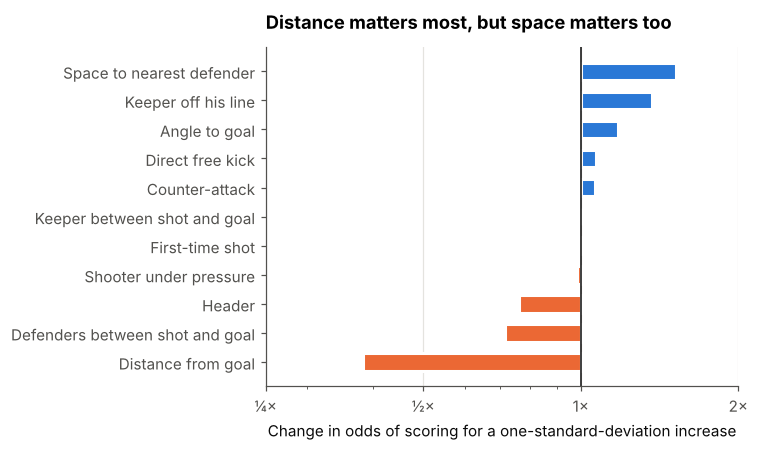

log_distance         0.38
defenders_in_cone    0.72
header               0.76
under_pressure       0.98
first_time           0.99
gk_in_cone           1.00
counter              1.07
free_kick            1.07
angle                1.18
gk_off_line          1.37
log_nearest          1.52
dtype: float64

In [6]:
# Refit on all shots to read the coefficients. Features are standardized so effects are comparable.
Xs = StandardScaler().fit_transform(npsh[FULL])
coef = pd.Series(LogisticRegression(max_iter=2000).fit(Xs, npsh.goal).coef_[0], index=FULL)
odds = np.exp(coef).sort_values()
labels = {"log_distance": "Distance from goal", "angle": "Angle to goal", "header": "Header",
    "first_time": "First-time shot", "under_pressure": "Shooter under pressure", "free_kick": "Direct free kick",
    "counter": "Counter-attack", "defenders_in_cone": "Defenders between shot and goal",
    "gk_in_cone": "Keeper between shot and goal", "gk_off_line": "Keeper off his line",
    "log_nearest": "Space to nearest defender"}

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh([labels[i] for i in odds.index], odds - 1, left=1, height=0.6,
        color=[BLUE if v > 1 else ORANGE for v in odds], edgecolor="white", linewidth=2)
ax.axvline(1, color=INK, linewidth=1)
ax.set_xscale("log"); ax.set_xticks([0.25, 0.5, 1, 2]); ax.set_xticklabels(["¼×", "½×", "1×", "2×"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("Change in odds of scoring for a one-standard-deviation increase")
ax.set_title("Distance matters most, but space matters too", pad=12)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("figures/xg_odds_ratios.png", dpi=150, bbox_inches="tight"); plt.show()
odds.round(2)

**Reading the chart.** Features were standardised, so each bar shows how the odds of scoring change when a feature rises by one standard deviation, holding everything else constant.
- **Distance dominates.** One standard deviation further out cuts the odds to about 0.38×.
- **Space matters a lot.** More room to the nearest defender (×1.52) and an extra body in the shooting lane (×0.72) are each about as important as the angle.
- **A keeper off his line** raises the odds (×1.37). That covers lobs and shots after the keeper has been rounded.
- **Headers** are harder to score than foot shots from the same spot (×0.76).
- Once defender positions are in the model, "under pressure" and "first-time" add almost nothing, because the freeze frame already captures that information.

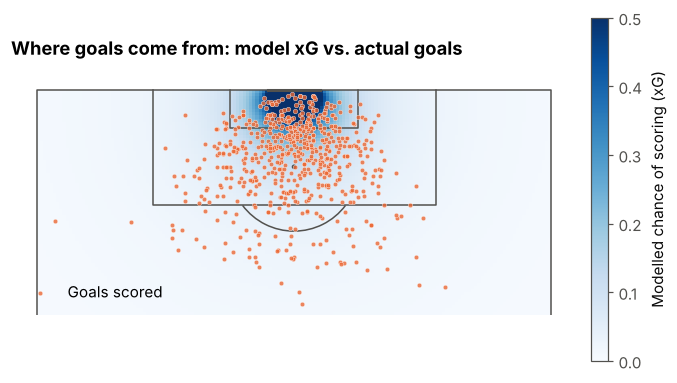

In [7]:
# Predict xG over a grid of pitch locations for an "average" open-play footed shot
model = LogisticRegression(max_iter=2000).fit(npsh[FULL], npsh.goal)
gx, gy = np.meshgrid(np.arange(60, 120, 0.5) + 0.25, np.arange(0, 80, 0.5) + 0.25)
dx, dy = 120 - gx, 40 - gy
ang = np.arctan2(8 * dx, dx**2 + dy**2 - 16); ang = np.where(ang < 0, ang + np.pi, ang)
grid = pd.DataFrame({"log_distance": np.log(np.hypot(dx, dy)).ravel(), "angle": ang.ravel()})
for f in FULL[2:]:
    grid[f] = npsh[f].median()                         # every other feature at its typical value
grid["defenders_in_cone"] = 1
xg_grid = model.predict_proba(grid[FULL])[:, 1].reshape(gx.shape)

pitch = VerticalPitch(half=True, pitch_type="statsbomb", line_color=MUTED, linewidth=1, pad_bottom=-25)
fig, ax = pitch.draw(figsize=(6.5, 5.5))
mesh = ax.pcolormesh(gy, gx, xg_grid, cmap="Blues", vmin=0, vmax=0.5, shading="auto", zorder=0)
goals = npsh[npsh.goal == 1]
pitch.scatter(goals.x, goals.y, s=9, color=ORANGE, alpha=0.8, edgecolors="white", linewidths=0.3, ax=ax, zorder=2, label="Goals scored")
cb = fig.colorbar(mesh, ax=ax, shrink=0.6, pad=0.02); cb.set_label("Modelled chance of scoring (xG)")
ax.legend(loc="lower left", frameon=False)
ax.set_title("Where goals come from: model xG vs. actual goals", loc="left", fontweight="bold")
plt.savefig("figures/xg_pitch_map.png", dpi=150, bbox_inches="tight"); plt.show()

The heat map shows the model's xG for an average footed shot with one defender in the way. Orange dots are the 668 real non-penalty goals. Probability drops steeply outside the six-yard box: most goals come from a small central zone, and the long-range ones are rare exceptions.

## 5. Q2: Who finished better or worse than expected, and were the champions lucky?
**Wrangling.** I aggregated the out-of-sample shot xG from Q1 into one row per team per tournament, then compared **non-penalty goals** with **non-penalty xG**. My team totals correlate with StatsBomb's at r = 0.986, so the conclusions don't depend on whose model is used.

**Is a gap luck or skill? A Monte Carlo simulation.** Scoring 3 goals more than expected sounds impressive, but finishing is noisy. To check, I simulated each team's tournament **20,000 times**, treating every shot as a weighted coin flip with probability equal to its xG. `p_at_least_this_many` is the share of simulations where the team scored at least as many goals as it really did. A value near 0 means the over-performance is very unlikely to be pure chance.

In [8]:
# Aggregate to one row per team per tournament. Non-penalty goals vs. our out-of-sample xG.
rng = np.random.default_rng(215)
def chance_of_at_least(g, n_sims=20_000):
    """Simulate every shot as a coin flip weighted by its xG; how often do we get >= the real goals?"""
    sims = (rng.random((n_sims, len(g))) < g.xg_full.values).sum(axis=1)
    return pd.Series({"p_at_least_this_many": (sims >= g.goal.sum()).mean(),
                      "p_at_most_this_many": (sims <= g.goal.sum()).mean()})

teams = (npsh.groupby(["tournament", "team"])
         .agg(matches=("match_id", "nunique"), shots=("goal", "size"), np_goals=("goal", "sum"),
              np_xg=("xg_full", "sum"), statsbomb_np_xg=("statsbomb_xg", "sum"))
         .join(npsh.groupby(["tournament", "team"])[["goal", "xg_full"]].apply(chance_of_at_least))
         .reset_index())
teams["goals_minus_xg"] = teams.np_goals - teams.np_xg
print("Correlation between our team xG and StatsBomb's:", round(teams.np_xg.corr(teams.statsbomb_np_xg), 3))
show = ["tournament", "team", "matches", "shots", "np_goals", "np_xg", "goals_minus_xg", "p_at_least_this_many", "p_at_most_this_many"]
teams.sort_values("goals_minus_xg", ascending=False)[show].round(2).head(8)

Correlation between our team xG and StatsBomb's: 0.986


,tournament,team,matches,shots,np_goals,np_xg,goals_minus_xg,p_at_least_this_many,p_at_most_this_many
8,AFCON 2023,Equatorial Guinea,4,30,9,3.31,5.69,0.00,1.00
110,World Cup 2018,Russia,5,49,9,3.71,5.29,0.01,1.00
130,World Cup 2022,England,5,61,12,6.86,5.14,0.03,0.99
138,World Cup 2022,Netherlands,5,43,10,4.86,5.14,0.01,1.00
140,World Cup 2022,Portugal,5,64,10,5.00,5.00,0.02,0.99
131,World Cup 2022,France,7,100,14,9.48,4.52,0.08,0.96
19,AFCON 2023,Senegal,4,44,9,4.71,4.29,0.03,0.99
84,Euro 2024,Spain,7,123,14,9.78,4.22,0.10,0.94


**Over-performers.** **Equatorial Guinea at AFCON 2023** scored 9 non-penalty goals from 3.3 xG. Fewer than 1 in 200 simulations got there by chance. Russia, hosts of the 2018 World Cup, did almost the same: 9 goals from 3.7 xG.

In [9]:
teams.sort_values("goals_minus_xg")[show].round(2).head(5)

,tournament,team,matches,shots,np_goals,np_xg,goals_minus_xg,p_at_least_this_many,p_at_most_this_many
71,Euro 2024,France,6,95,1,6.81,-5.81,1.00,0.01
5,AFCON 2023,Congo DR,7,90,5,10.29,-5.29,0.99,0.03
99,World Cup 2018,Germany,3,73,2,6.83,-4.83,1.00,0.02
78,Euro 2024,Portugal,5,87,3,7.73,-4.73,0.99,0.03
91,World Cup 2018,Brazil,5,103,8,12.57,-4.57,0.97,0.07


**Under-performers.** **France at Euro 2024** produced 6.8 xG and scored *one* non-penalty goal from a shot (their other goals were own goals and a penalty). Only about 1% of simulations finish that poorly. They still reached the semi-final.

In [10]:
# Join in who won each tournament
winners = {"World Cup 2018": "France", "World Cup 2022": "Argentina", "Euro 2020": "Italy",
           "Euro 2024": "Spain", "AFCON 2023": "Côte d'Ivoire", "Copa America 2024": "Argentina"}
champs = teams[teams.apply(lambda r: winners[r.tournament] == r.team, axis=1)]
champs[show].round(2)

,tournament,team,matches,shots,np_goals,np_xg,goals_minus_xg,p_at_least_this_many,p_at_most_this_many
6,AFCON 2023,Côte d'Ivoire,7,96,7,7.93,-0.93,0.69,0.45
24,Copa America 2024,Argentina,6,82,9,10.39,-1.39,0.76,0.38
50,Euro 2020,Italy,7,126,12,10.99,1.01,0.41,0.71
84,Euro 2024,Spain,7,123,14,9.78,4.22,0.10,0.94
98,World Cup 2018,France,7,79,9,6.07,2.93,0.13,0.94
120,World Cup 2022,Argentina,7,96,11,9.10,1.90,0.30,0.82


**The champions were mostly not lucky.** Five of the six winners finished within about 3 goals of their xG, and none was far enough above it to call it fluke finishing (every `p_at_least_this_many` ≥ 0.10).
- **Côte d'Ivoire won AFCON 2023 while slightly *under*-finishing** (7 goals from 7.9 xG). Their run had famous late drama, but in front of goal they weren't lucky.
- **Argentina won Copa América 2024 the same way** (9 goals from 10.4 xG).
- **Spain at Euro 2024** were the hottest finishers (+4.2). That is still within normal variance (p = 0.10), and they also created the most chances of any team.

Champions win by **creating a lot**, not by finishing miraculously.

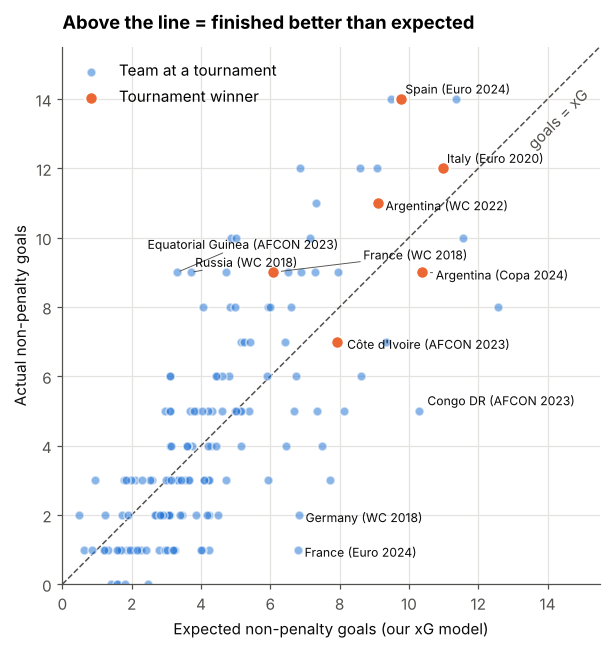

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
lim = teams[["np_xg", "np_goals"]].max().max() + 1.5
ax.plot([0, lim], [0, lim], color=MUTED, linewidth=1, linestyle="--", zorder=1)
ax.text(lim - 0.3, lim - 1.4, "goals = xG", color=MUTED, ha="right", rotation=45, rotation_mode="anchor")
others = teams.drop(champs.index)
ax.scatter(others.np_xg, others.np_goals, s=34, color=BLUE, alpha=0.55, edgecolors="white", linewidths=1, label="Team at a tournament")
ax.scatter(champs.np_xg, champs.np_goals, s=70, color=ORANGE, edgecolors="white", linewidths=1.5, zorder=3, label="Tournament winner")
texts = []
for _, r in pd.concat([champs, teams.nlargest(2, "goals_minus_xg"), teams.nsmallest(3, "goals_minus_xg")]).drop_duplicates().iterrows():
    short = r.tournament.replace("World Cup ", "WC ").replace("Copa America ", "Copa ")
    texts.append(ax.text(r.np_xg, r.np_goals, f"{r.team} ({short})", fontsize=8, color=INK))
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal")
ax.set_xlabel("Expected non-penalty goals (our xG model)"); ax.set_ylabel("Actual non-penalty goals")
ax.set_title("Above the line = finished better than expected", pad=12)
ax.legend(loc="upper left", frameon=False)
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
plt.tight_layout(); plt.savefig("figures/goals_vs_xg.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Q3: Do teams fall into distinct styles, and has the game changed?
**A data-quality check first.** The raw number of pressures per team per match drops from **183 at World Cup 2018 to 129 at World Cup 2022**. Teams didn't suddenly stop pressing; StatsBomb's collection process changed between releases. Raw pressure counts aren't comparable across tournaments, so I **left them out** and used shares and locations instead, which hold up better against that kind of change.

In [12]:
STYLE = ["possession_share", "pass_completion", "avg_pass_length", "long_pass_share",
         "forward_pass_share", "press_height", "high_press_share"]
print("Average pressures per team per match:")
print(style.groupby("tournament").pressures.mean().round(0))

Average pressures per team per match:
tournament
AFCON 2023           144.0
Copa America 2024    143.0
Euro 2020            156.0
Euro 2024            142.0
World Cup 2018       183.0
World Cup 2022       129.0
Name: pressures, dtype: float64


**Method.**
1. Average each team's per-match style metrics over its tournament (152 team-tournaments, 3 to 7 matches each).
2. **Standardise** each metric (z-scores), so pass length in yards doesn't outweigh shares between 0 and 1.
3. **PCA** compresses the 7 metrics into 2 axes for plotting.
4. **K-means** groups similar teams. I checked k = 2 to 6 with the **silhouette score**, which measures how well-separated the clusters are.

In [13]:
# One row per team per tournament: average its per-match style numbers (teams play 3 to 7 matches)
ts = (style.groupby(["tournament", "team"])[STYLE].mean()
      .join(teams.set_index(["tournament", "team"])[["np_goals", "np_xg", "matches"]]).reset_index())
X = StandardScaler().fit_transform(ts[STYLE])              # put every metric on the same scale

pca = PCA().fit(X)
print("Variance explained by each component:", pca.explained_variance_ratio_.round(2))
loadings = pd.DataFrame(pca.components_[:2].T, index=STYLE, columns=["PC1", "PC2"]).round(2)
print(loadings)
for k in range(2, 7):
    print(f"k={k}: silhouette = {silhouette_score(X, KMeans(k, n_init=20, random_state=0).fit_predict(X)):.3f}")

Variance explained by each component: [0.7  0.19 0.04 0.03 0.02 0.01 0.01]
                     PC1   PC2
possession_share   -0.39  0.16
pass_completion    -0.41 -0.19
avg_pass_length     0.38  0.35
long_pass_share     0.41  0.24
forward_pass_share  0.38  0.33
press_height       -0.33  0.58
high_press_share   -0.33  0.56
k=2: silhouette = 0.383
k=3: silhouette = 0.261
k=4: silhouette = 0.257
k=5: silhouette = 0.257


k=6: silhouette = 0.244


**Style is mostly one-dimensional.** PC1 alone explains **70%** of the variation. It runs from *short passes, high completion, lots of the ball* to *long, direct, forward passing*. PC2 (19%) is *where you press*. k = 2 has the best silhouette score (0.38), but it only splits "has the ball" from "doesn't". I chose **k = 3**, which scores almost as well as k = 4 or 5 and adds a meaningful middle group. The trade-off: these are regions of a continuum rather than sharply separate types.

In [14]:
K = 3
ts["cluster"] = KMeans(K, n_init=20, random_state=0).fit_predict(X)
pcs = pca.transform(X)
# PCA signs are arbitrary; flip PC1 so that "keeps the ball" points right (possession loads negative above)
ts["PC1"], ts["PC2"] = -pcs[:, 0], pcs[:, 1]
profile = ts.groupby("cluster")[STYLE].mean()
profile["teams"] = ts.groupby("cluster").size()
profile.round(2)

,possession_share,pass_completion,avg_pass_length,long_pass_share,forward_pass_share,press_height,high_press_share,teams
cluster,,,,,,,,
0,0.58,0.86,19.96,0.11,0.29,60.30,0.28,42
1,0.41,0.76,22.71,0.17,0.37,53.08,0.19,49
2,0.49,0.83,20.88,0.13,0.32,53.68,0.20,61


The three groups:
- **Possession & high press** (42 teams): 58% of passes, 86% completion, pressing well into the opponent's half
- **Balanced** (61 teams): around 50% possession, a mid-height press
- **Direct / low-block** (49 teams): 41% of passes, longer and more forward passing, a deeper press

In [15]:
# Name clusters from their profiles (lowest possession -> "Low-block", highest -> "Possession")
order = profile.possession_share.sort_values().index
names = dict(zip(order, ["Direct / low-block", "Balanced", "Possession & high press"]))
ts["style"] = ts.cluster.map(names)
recent = ts[ts.tournament.isin(["World Cup 2022", "Euro 2024", "AFCON 2023"])]
for s_name, d in recent.groupby("style"):
    d = d.sort_values("PC1", ascending=False)
    print(f"{s_name}: " + ", ".join((d.team + " '" + d.tournament.str[-2:]).head(10)))
pd.crosstab(ts.tournament, ts["style"])

Balanced: Turkey '24, Netherlands '22, Ukraine '24, Belgium '22, Mali '23, Guinea-Bissau '23, Switzerland '22, France '22, Serbia '22, Scotland '24
Direct / low-block: Wales '22, Mexico '22, Burkina Faso '23, Japan '22, Congo DR '23, Guinea '23, Morocco '22, Senegal '22, Saudi Arabia '22, Nigeria '23
Possession & high press: Spain '22, Germany '24, Portugal '24, Germany '22, Croatia '24, Spain '24, Brazil '22, England '22, Denmark '24, Portugal '22


style,Balanced,Direct / low-block,Possession & high press
tournament,,,
AFCON 2023,11,8,5
Copa America 2024,4,8,4
Euro 2020,11,8,5
Euro 2024,8,3,13
World Cup 2018,18,9,5
World Cup 2022,9,13,10


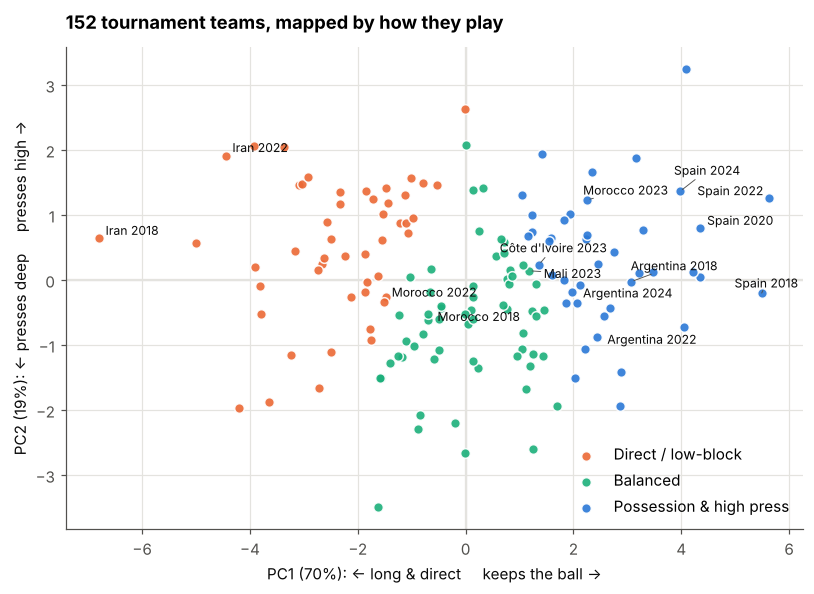

In [16]:
colors = {"Direct / low-block": ORANGE, "Balanced": AQUA, "Possession & high press": BLUE}
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for s_name, c in colors.items():
    d = ts[ts["style"] == s_name]
    ax.scatter(d.PC1, d.PC2, s=40, color=c, edgecolors="white", linewidths=1, label=s_name, alpha=0.9)
texts = []
for _, r in ts[ts.team.isin(["Spain", "Argentina", "Côte d'Ivoire", "Morocco", "Mali", "Iran"])].iterrows():
    texts.append(ax.text(r.PC1, r.PC2, f"{r.team} {r.tournament[-4:]}", fontsize=8, color=INK))
ax.axhline(0, color=GRID, zorder=0); ax.axvline(0, color=GRID, zorder=0)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%}): ← long & direct     keeps the ball →")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%}): ← presses deep     presses high →")
ax.set_title(f"{len(ts)} tournament teams, mapped by how they play", pad=12)
ax.legend(frameon=False, loc="lower right")
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
plt.tight_layout(); plt.savefig("figures/style_clusters.png", dpi=150, bbox_inches="tight"); plt.show()

Spain sits at the far possession end at all four of its tournaments, and Iran sits at the far direct end. Côte d'Ivoire 2023 lands in the possession group and Mali 2023 in the balanced group. **Morocco is the most interesting case.** The same core squad went from balanced (2018) to direct (2022, when it reached the World Cup semi-final by defending deep against stronger teams) to possession (AFCON 2023, as favourites). A team's style depends on who it is playing, not just on who it is.

Every tournament contains all three styles, so **no continent has a single "way of playing"**. Euro 2024 has the most possession teams (13 of 24).

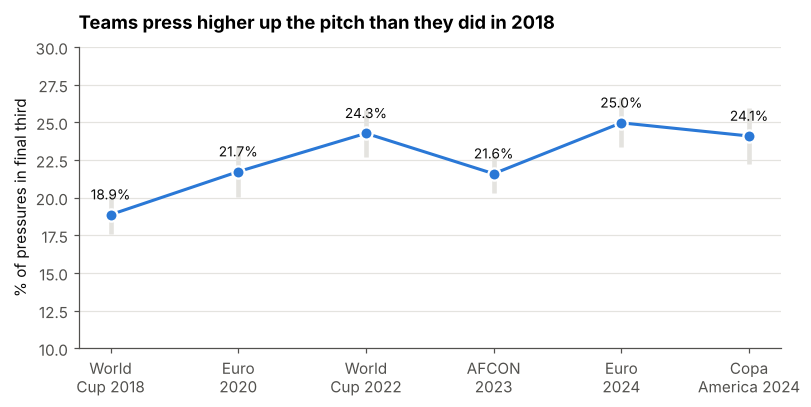

,high_press_share,press_height,long_pass_share
tournament,,,
World Cup 2018,0.189,53.584,0.141
Euro 2020,0.217,55.482,0.132
World Cup 2022,0.243,57.090,0.130
AFCON 2023,0.216,54.974,0.142
Euro 2024,0.250,57.041,0.113
Copa America 2024,0.241,56.767,0.145


In [17]:
# Is the high press spreading? Share of pressures in the final third, per tournament, in date order
when = ["World Cup 2018", "Euro 2020", "World Cup 2022", "AFCON 2023", "Euro 2024", "Copa America 2024"]
trend = style.groupby("tournament")[["high_press_share", "press_height", "long_pass_share"]].mean().loc[when]
spread = style.groupby("tournament").high_press_share.sem().loc[when] * 1.96

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.errorbar(range(len(when)), trend.high_press_share * 100, yerr=spread * 100, fmt="o-", color=BLUE,
            linewidth=2, markersize=8, markeredgecolor="white", markeredgewidth=1.5, capsize=0, ecolor=GRID, elinewidth=3)
for i, v in enumerate(trend.high_press_share * 100):
    ax.annotate(f"{v:.1f}%", (i, v), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.set_xticks(range(len(when))); ax.set_xticklabels([w.replace(" ", "\n", 1) for w in when])
ax.set_ylabel("% of pressures in final third"); ax.set_ylim(10, 30)
ax.set_title("Teams press higher up the pitch than they did in 2018", pad=12)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig("figures/press_trend.png", dpi=150, bbox_inches="tight"); plt.show()
trend.round(3)

**The press has moved up the pitch.** The share of pressures made in the final third rose from **18.9% at World Cup 2018 to 24–25% at World Cup 2022, Euro 2024 and Copa América 2024**. The grey bars are 95% confidence intervals, and 2018 doesn't overlap with 2022 or 2024. Long passing fell at the Euros, from 13.2% to 11.3%. AFCON 2023 is the exception, at the same pressing level as Euro 2020.

*Caveat:* these are location-based shares, so they're far less sensitive to how many pressures get logged. Still, a change in what StatsBomb counts as a "pressure" could shift them a little.

In [18]:
# Does style relate to attacking output? Non-penalty xG per match by style
ts["np_xg_per_match"] = ts.np_xg / ts.matches
ts.groupby("style")[["np_xg_per_match"]].agg(["mean", "count"]).round(2)

np_xg_per_match      
                                   mean count
style                                        
Balanced                           0.95    61
Direct / low-block                 0.86    49
Possession & high press            1.34    42

**Does style relate to chance creation?** Yes. Possession & high-press teams averaged **1.34 non-penalty xG per match**, against 0.95 for balanced teams and 0.86 for direct ones. Causation runs both ways, though: better teams *get* the ball more, so this doesn't prove possession *causes* chances.

## 7. Summary of findings
1. **Shot quality comes down to distance and space.** A simple logistic regression with defender positions comes within 0.015 AUC of StatsBomb's professional model.
2. **Big finishing gaps happen, but champions rarely depend on them.** France at Euro 2024 and Equatorial Guinea at AFCON 2023 were genuine statistical outliers. The winners mostly won by creating the most chances; Côte d'Ivoire and Argentina 2024 actually under-finished.
3. **Style is mostly a single axis**, from possession to direct play, and every continent covers that whole range. Since 2018, teams press noticeably higher.

### Limitations and extensions
- Tournament samples are small (3 to 7 matches per team), so most single-team finishing gaps are noise. That is exactly why the simulation matters.
- Freeze frames record positions only, with no player speed or body orientation.
- With more time I would: add StatsBomb 360 data to measure *defensive line* height directly; include women's tournaments (Women's World Cup 2019/2023, Women's Euro 2022/2025) for comparison; and try a gradient-boosted model to see whether a non-linear model beats logistic regression.

## 8. New techniques and how I learned them
| technique | why I used it | how I learned it |
|---|---|---|
| **Logistic regression** (xG model) | The outcome is binary (goal or no goal), and I wanted a probability rather than a label | [scikit-learn LogisticRegression docs](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html); [Expected Goals lecture, STAT 479, UW–Madison](https://skdeshpande91.github.io/stat479_fall2025/lectures/lecture02.html) |
| **Grouped cross-validation** | Shots from one match aren't independent, so splitting at random would leak information | [GroupKFold docs](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html) |
| **Monte Carlo simulation** | To tell luck from skill without assuming a formula | Built from the definition of xG: each shot is a Bernoulli trial |
| **Point-in-triangle test** | To count defenders inside the shooting lane | Cross-product sign method (standard computational geometry) |
| **Pitch plots** with mplsoccer | Shot data only makes sense drawn on a pitch | [mplsoccer docs and examples](https://mplsoccer.readthedocs.io/) |

PCA, standardisation and k-means came from class; the silhouette score was new (see the [scikit-learn clustering guide](https://scikit-learn.org/stable/modules/clustering.html#k-means)).

## 9. Sources and credits
- Data: [StatsBomb Open Data](https://github.com/statsbomb/open-data) (Hudl StatsBomb)
- [What are Expected Goals? (Hudl StatsBomb)](https://www.hudl.com/blog/expected-goals-xg-explained)
- Library docs: pandas, scikit-learn, matplotlib, mplsoccer, adjustText
- **AI assistance:** I used Claude (Anthropic) to help scaffold the data pipeline, debug the freeze-frame parsing, and draft parts of this narrative. I reviewed, ran and edited all code and text. *[Ahmed: edit to reflect exactly how you used it]*

## 10. Reflection
*[Ahmed: write this section in your own words. Some prompts:]*
- **What surprised me:** *e.g. how little the champions depended on finishing luck; that the raw pressure counts changed between data releases*
- **What was challenging:** *e.g. navigating the nested JSON, deciding how many clusters to use when the "best" number wasn't the most useful one*
- **What I'd do differently:**